<a href="https://colab.research.google.com/github/TamannaSwarna140/AB_Test_Cookie_Cats/blob/main/AB_Test_Cookie_Cats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A/B Test Analysis: Does Moving a Game Gate Change Player Retention?

**Author:** Tamanna Akter Swarna

This project analyses a randomised experiment on the mobile game *Cookie Cats*. The first gate in the game was moved
from level 30 to level 40, and each new player was randomly assigned to one version. The analysis tests whether the change
affects player retention and ends with a ship / don't-ship recommendation.

The method (randomised groups, hypothesis tests on conversion-style rates, confidence intervals, power) is the same one
used to evaluate a landing page, an email subject line or a pricing change.

## Summary of results

**Question:** Does moving the first gate from level 30 to level 40 change retention?

**Data:** 90,189 players: 44,700 in `gate_30` (control) and 45,489 in `gate_40` (treatment)

**Day-1 retention:** 44.82% vs 44.23% (difference -0.59 percentage points, 95% CI -1.24 to +0.06, p = 0.074). No significant difference.

**Day-7 retention:** 19.02% vs 18.20% (difference -0.82 percentage points, 95% CI -1.33 to -0.31, p = 0.0016). A significant drop of 4.3% in relative terms.

**Robustness:** The day-7 result holds after a Bonferroni correction for two metrics and in a bootstrap analysis.

**Game rounds played:** Median 17 vs 16, Mann-Whitney p = 0.050. No clear difference.

**Validity check:** Group sizes are slightly unbalanced (sample ratio test p = 0.0086). Noted as a caution.

**Recommendation:** Keep the gate at level 30.

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

## 2. Experiment design

**Setup.** When a player installed the game, they were randomly assigned to `gate_30` (the existing design, used as control)
or `gate_40` (the proposed design, used as treatment).

**Metrics**
- *Primary:* 1-day retention and 7-day retention (did the player come back 1 and 7 days after installing).
- *Secondary:* total game rounds played in the first 14 days.

**Hypotheses** (for each primary metric, two-sided)
- H0: moving the gate has no effect on retention.
- H1: moving the gate changes retention.

**Decision rule.** Significance level of 0.05. Because two primary metrics are tested, a Bonferroni-corrected
level of 0.025 is also applied.

## 3. Data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/yanny-alt/Cookie-Cats-A-B-Testing-Project/main/data/cookie_cats.csv"
df = pd.read_csv(DATA_URL)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.info()
print("\nMissing values:", int(df.isna().sum().sum()))
print("Duplicate user IDs:", df["userid"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB

Missing values: 0
Duplicate user IDs: 0


Columns: `userid` (player ID), `version` (assigned group), `sum_gamerounds` (rounds played in the first 14 days),
`retention_1` and `retention_7` (returned after 1 and 7 days). There are no missing values or duplicate players.
The retention columns are converted to 0/1 for the calculations.

In [4]:
df["retention_1"] = df["retention_1"].astype(int)
df["retention_7"] = df["retention_7"].astype(int)

control = df[df["version"] == "gate_30"]
treatment = df[df["version"] == "gate_40"]
print(df["version"].value_counts())

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64


## 4. Experiment validity: sample ratio check

With random assignment into two equal groups, the split should be close to 50/50. A chi-square test checks whether the
observed split is consistent with that.

gate_30: 44,700 (49.56%)
gate_40: 45,489 (50.44%)
Chi-square = 6.90, p = 0.0086


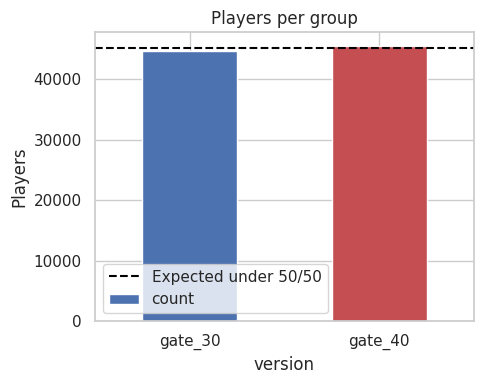

In [5]:
counts = df["version"].value_counts().reindex(["gate_30", "gate_40"])
chi2, p_srm = stats.chisquare(counts.values)
print(f"gate_30: {counts['gate_30']:,} ({counts['gate_30'] / counts.sum():.2%})")
print(f"gate_40: {counts['gate_40']:,} ({counts['gate_40'] / counts.sum():.2%})")
print(f"Chi-square = {chi2:.2f}, p = {p_srm:.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
counts.plot(kind="bar", color=["#4C72B0", "#C44E52"], rot=0, ax=ax)
ax.axhline(counts.sum() / 2, color="black", linestyle="--", label="Expected under 50/50")
ax.set_title("Players per group")
ax.set_ylabel("Players")
ax.legend()
plt.tight_layout()
plt.savefig("images/01_group_sizes.png", dpi=150)
plt.show()

**Finding:** `gate_40` holds 50.44% of players. The imbalance is small but statistically detectable (p = 0.0086).
Sample ratio mismatches are usually treated as a serious warning only at much smaller p-values (a common threshold is 0.001),
so the experiment is kept in the analysis, but the result is read with this caution in mind: it may point to a minor
assignment or logging issue that cannot be investigated with this dataset.

## 5. Retention results

A helper compares two proportions with a pooled two-proportion z-test and returns the absolute difference, its
95% confidence interval and the p-value. Differences are always `gate_40` minus `gate_30`.

In [6]:
def compare_proportions(a, b, alpha=0.05):
    """Two-sided pooled z-test for a difference in proportions (b minus a)."""
    na, nb = len(a), len(b)
    pa, pb = a.mean(), b.mean()
    pooled = (a.sum() + b.sum()) / (na + nb)
    z = (pb - pa) / np.sqrt(pooled * (1 - pooled) * (1 / na + 1 / nb))
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    se = np.sqrt(pa * (1 - pa) / na + pb * (1 - pb) / nb)
    crit = stats.norm.ppf(1 - alpha / 2)
    diff = pb - pa
    return {"rate_control": pa, "rate_treatment": pb, "diff": diff,
            "ci_low": diff - crit * se, "ci_high": diff + crit * se,
            "relative_change": diff / pa, "z": z, "p_value": p_value}

results = {m: compare_proportions(control[m], treatment[m]) for m in ["retention_1", "retention_7"]}

table = pd.DataFrame(results).T
table.index = ["Day-1 retention", "Day-7 retention"]
table["significant at 0.05"] = table["p_value"] < 0.05
table["significant at 0.025 (Bonferroni)"] = table["p_value"] < 0.025
display(table.round(4))

,rate_control,rate_treatment,diff,ci_low,ci_high,relative_change,z,p_value,significant at 0.05,significant at 0.025 (Bonferroni)
Day-1 retention,0.4482,0.4423,-0.0059,-0.0124,0.0006,-0.0132,-1.7841,0.0744,False,False
Day-7 retention,0.1902,0.1820,-0.0082,-0.0133,-0.0031,-0.0431,-3.1644,0.0016,True,True


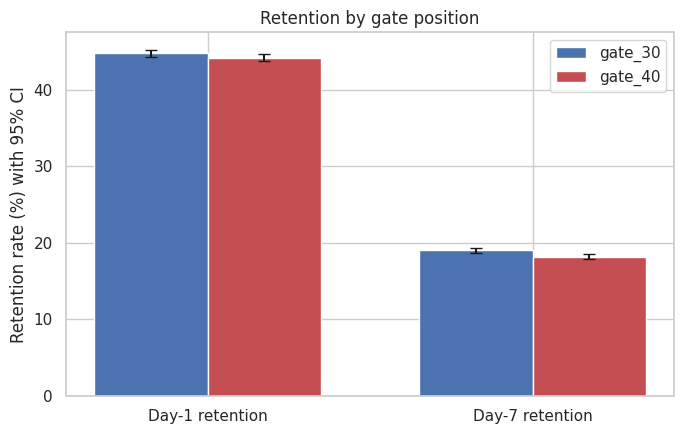

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2)
width = 0.35
for i, (label, color) in enumerate([("gate_30", "#4C72B0"), ("gate_40", "#C44E52")]):
    grp = control if label == "gate_30" else treatment
    rates, errs = [], []
    for m in ["retention_1", "retention_7"]:
        p, n = grp[m].mean(), len(grp)
        rates.append(p * 100)
        errs.append(1.96 * np.sqrt(p * (1 - p) / n) * 100)
    ax.bar(x + (i - 0.5) * width, rates, width, yerr=errs, capsize=4, label=label, color=color)
ax.set_xticks(x)
ax.set_xticklabels(["Day-1 retention", "Day-7 retention"])
ax.set_ylabel("Retention rate (%) with 95% CI")
ax.set_title("Retention by gate position")
ax.legend()
plt.tight_layout()
plt.savefig("images/02_retention_rates.png", dpi=150)
plt.show()

**Finding (day 1):** retention is 44.82% with the gate at level 30 and 44.23% at level 40. The difference of -0.59 percentage
points is not statistically significant (p = 0.074); the confidence interval (-1.24 to +0.06 points) includes zero.

**Finding (day 7):** retention is 19.02% at level 30 and 18.20% at level 40. The difference of -0.82 percentage points
(-4.3% in relative terms) is statistically significant (p = 0.0016). The confidence interval (-1.33 to -0.31 points) lies
entirely below zero, and the result also passes the Bonferroni-corrected threshold of 0.025.

## 6. Bootstrap confirmation

The z-test relies on a normal approximation. A bootstrap provides a check that does not depend on it. Resampling a
0/1 outcome with replacement is equivalent to drawing from a binomial distribution with the observed rate, so each
bootstrap replicate is drawn that way (10,000 replicates).

,95% CI low,95% CI high,Share of replicates with gate_40 lower
Day-1 retention,-0.0125,0.0006,0.9653
Day-7 retention,-0.0132,-0.0031,0.9990


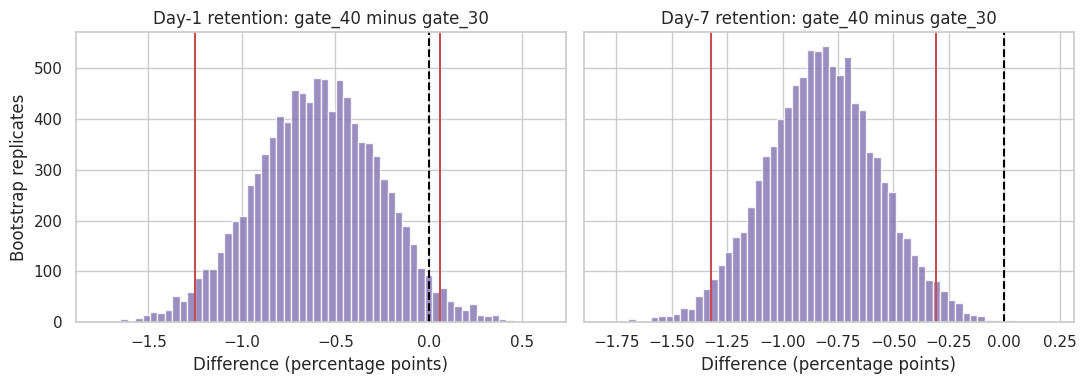

In [8]:
N_BOOT = 10_000
boot = {}
for m in ["retention_1", "retention_7"]:
    sim_c = rng.binomial(len(control), control[m].mean(), N_BOOT) / len(control)
    sim_t = rng.binomial(len(treatment), treatment[m].mean(), N_BOOT) / len(treatment)
    boot[m] = sim_t - sim_c

summary_boot = pd.DataFrame({
    "95% CI low": {m: np.percentile(d, 2.5) for m, d in boot.items()},
    "95% CI high": {m: np.percentile(d, 97.5) for m, d in boot.items()},
    "Share of replicates with gate_40 lower": {m: (d < 0).mean() for m, d in boot.items()},
})
summary_boot.index = ["Day-1 retention", "Day-7 retention"]
display(summary_boot.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (m, label) in zip(axes, [("retention_1", "Day-1 retention"), ("retention_7", "Day-7 retention")]):
    ax.hist(boot[m] * 100, bins=60, color="#8172B2", alpha=0.8)
    ax.axvline(0, color="black", linestyle="--")
    lo, hi = np.percentile(boot[m], [2.5, 97.5]) * 100
    ax.axvline(lo, color="#C44E52")
    ax.axvline(hi, color="#C44E52")
    ax.set_title(f"{label}: gate_40 minus gate_30")
    ax.set_xlabel("Difference (percentage points)")
axes[0].set_ylabel("Bootstrap replicates")
plt.tight_layout()
plt.savefig("images/03_bootstrap_differences.png", dpi=150)
plt.show()

**Finding:** The bootstrap intervals match the z-test intervals. For day 7, the interval (-1.32 to -0.31 points) excludes zero
and `gate_40` is lower in 99.9% of replicates. For day 1, the interval still includes zero, with `gate_40` lower in 96.5% of
replicates: the data lean towards a small decrease but do not establish it.

## 7. Sensitivity: what effect size can this experiment detect?

A non-significant result is only informative if the test had enough power. The minimum detectable effect (MDE) at 80% power and
a 5% significance level, given the observed sample sizes and the control retention rate, is:

In [9]:
z_alpha = stats.norm.ppf(0.975)
z_beta = stats.norm.ppf(0.80)

mde_rows = {}
for m, label in [("retention_1", "Day-1 retention"), ("retention_7", "Day-7 retention")]:
    p = control[m].mean()
    mde = (z_alpha + z_beta) * np.sqrt(p * (1 - p) * (1 / len(control) + 1 / len(treatment)))
    mde_rows[label] = {"Control rate": p, "MDE (absolute, pp)": mde * 100,
                       "Observed difference (pp)": results[m]["diff"] * 100}
display(pd.DataFrame(mde_rows).T.round(3))

,Control rate,"MDE (absolute, pp)",Observed difference (pp)
Day-1 retention,0.448,0.928,-0.591
Day-7 retention,0.190,0.732,-0.820


**Finding:** The experiment can reliably detect absolute differences of about 0.93 percentage points in day-1 retention and
0.73 points in day-7 retention. The observed day-1 difference (-0.59 points) is smaller than its MDE, so the day-1 result
is inconclusive rather than evidence of no effect. The observed day-7 difference (-0.82 points) is just above its MDE,
consistent with the significant result.

## 8. Secondary metric: game rounds played

Rounds played are heavily right-skewed, with a few extreme players, so a rank-based test (Mann-Whitney U) is used
instead of a comparison of means.

         median   mean    max
version                      
gate_30    17.0  52.46  49854
gate_40    16.0  51.30   2640

Players with zero rounds: 3994 (4.4%)

Mann-Whitney U p-value: 0.0502


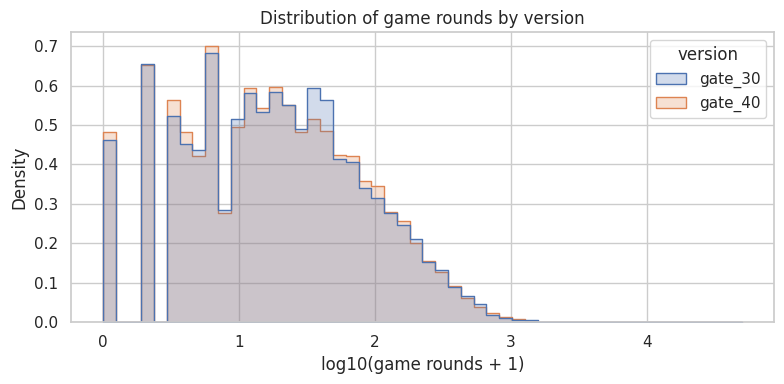

In [10]:
print(df.groupby("version")["sum_gamerounds"].agg(["median", "mean", "max"]).round(2))
print("\nPlayers with zero rounds:", (df["sum_gamerounds"] == 0).sum(),
      f"({(df['sum_gamerounds'] == 0).mean():.1%})")

u, p_mw = stats.mannwhitneyu(control["sum_gamerounds"], treatment["sum_gamerounds"], alternative="two-sided")
print(f"\nMann-Whitney U p-value: {p_mw:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x=np.log10(df["sum_gamerounds"] + 1), hue="version", bins=50,
             stat="density", common_norm=False, element="step", ax=ax)
ax.set_xlabel("log10(game rounds + 1)")
ax.set_title("Distribution of game rounds by version")
plt.tight_layout()
plt.savefig("images/04_gamerounds_distribution.png", dpi=150)
plt.show()

**Finding:** The median is 17 rounds in `gate_30` and 16 in `gate_40`. The Mann-Whitney test gives p = 0.050, which sits on the
threshold and is not a clear difference. One `gate_30` player recorded 49,854 rounds, an extreme outlier that the rank-based
test is not sensitive to. 4.4% of players installed the game and never played a round.

## 9. Decision

**Recommendation: keep the gate at level 30.**

- Moving the gate to level 40 lowers 7-day retention by about 0.8 percentage points (a 4.3% relative drop). The effect is
  statistically significant, robust to the multiple-testing correction, and confirmed by the bootstrap.
- Day-1 retention and game rounds show no reliable difference, so there is no offsetting benefit in the metrics measured here.
- The effect is small in absolute terms. Whether it matters commercially depends on what a retained player is worth, which
  this dataset does not contain.

### Limitations
- The sample ratio check shows a small imbalance between groups (p = 0.0086) that cannot be explained with the available data.
- Only short-term retention (1 and 7 days) and rounds played were measured. Revenue, purchases and long-term retention are
  unknown, and a change that lowers retention could still increase revenue.
- Retention is a single yes/no outcome at fixed days, so it ignores how engaged returning players are.
- The test was run once, with no sequential monitoring or pre-registration, and the analysis is based on a public copy of the data.

### Next steps
- Measure revenue per player and long-term retention (day 14 and day 30) to value the effect.
- Check consistency across player segments (for example by platform or acquisition source) if that data is available.
- Investigate the cause of the sample ratio imbalance before running the next experiment.